# Asistente RAG para datasheets y manuales de mecatrónica

**Proyecto final de Inteligencia Artificial (18314) · UMNG · 2026-2 · Teoría A**
**Estrategia permitida:** GPT personalizado / RAG (generación aumentada por recuperación)
**Autor:** Esteban Felipe Monroy Contreras · **Equipo:** _(completar integrantes)_

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EfMC/rag-datasheets-mecatronica/blob/main/notebooks/Proyecto_RAG_datasheets.ipynb)

Este notebook reúne todo el proyecto en un solo lugar: el problema, los datos, la
implementación, los experimentos y el análisis. Las tablas y gráficas se calculan aquí
mismo a partir de los resultados guardados en el repositorio, así que se puede leer sin
ejecutarlo; quien lo ejecute obtiene los mismos números.

**Resultado principal:** con 66 preguntas verificadas en los PDF, el asistente acierta
**0,83** (IC 95 % [0,75; 0,92]) frente a **0,58** del mismo modelo sin documentos
(+0,26; p = 0,003), y las alucinaciones bajan del **21 %** al **2 %**.

| Sección | Contenido | Evidencia | Criterio |
|---|---|---|---|
| 1 | Configuración del entorno | — | — |
| 2 | Problema, antecedentes y fundamentos | E1 | C1 |
| 3 | Datos: origen, calidad y preparación | E2 | C1, C2 |
| 4 | Diseño e implementación | E3 | C2 |
| 5 | Diseño de experimentos y resultados | E4 | C3 |
| 6 | Análisis de errores, limitaciones y conclusiones | E5 | C3 |
| 7 | Referencias | E1 | C1 |

Código: [github.com/EfMC/rag-datasheets-mecatronica](https://github.com/EfMC/rag-datasheets-mecatronica).
Documentación detallada en el repositorio: `ANTECEDENTES.md`, `DECISIONES.md` (25 decisiones
D1–D25) y `RESULTADOS.md`.

## 1. Configuración del entorno

La celda siguiente prepara todo. En Colab clona el repositorio e instala las dependencias.

Hay tres niveles de uso:

| Nivel | Qué necesita | Qué se puede ejecutar |
|---|---|---|
| Lectura | Nada | Secciones 2, 5 y 6 completas: métricas, gráficas y estadística desde `reportes/` (público) |
| Base de conocimiento | Secreto de Colab `GH_TOKEN_DATOS` (token de solo lectura del repo privado de los PDF) | Además, estadísticas del corpus, fragmentos y búsqueda en vivo (secciones 3 y 4) |
| Asistente completo | Además, secreto `GEMINI_API_KEY` (clave gratuita en aistudio.google.com/apikey) | Además, respuestas del asistente |

Los PDF están en un repositorio privado por derechos de autor de los fabricantes; el docente
puede pedir acceso. Los secretos se agregan en Colab con el ícono de la llave 🔑 del panel
izquierdo.

In [1]:
import base64, os, subprocess, sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
os.environ.update({"TRANSFORMERS_VERBOSITY": "error", "HF_HUB_DISABLE_PROGRESS_BARS": "1",
                   "TOKENIZERS_PARALLELISM": "false", "HF_HUB_VERBOSITY": "error"})
REPO = "https://github.com/EfMC/rag-datasheets-mecatronica.git"
REPO_DATOS = "EfMC/rag-datasheets-datos"
EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    raiz = Path("/content/rag-datasheets-mecatronica")
    if not raiz.exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, str(raiz)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pymupdf==2.1", "rank-bm25==0.2.2",
                    "google-genai==3.0.0", "sentence-transformers==6.2.0", "python-dotenv"], check=True)
    from google.colab import userdata

    def secreto(nombre):
        try:
            return (userdata.get(nombre) or "").strip()
        except Exception:
            return ""

    token = secreto("GH_TOKEN_DATOS")
    if token and not (raiz / "conocimiento").exists():
        cred = base64.b64encode(f"x-access-token:{token}".encode()).decode()
        subprocess.run(["git", "-c", f"http.https://github.com/.extraheader=AUTHORIZATION: basic {cred}",
                        "clone", "-q", "--depth", "1", f"https://github.com/{REPO_DATOS}.git",
                        str(raiz / "conocimiento")], check=False)
    if secreto("GEMINI_API_KEY"):
        os.environ["GEMINI_API_KEY"] = secreto("GEMINI_API_KEY")
else:
    raiz = Path.cwd() if (Path.cwd() / "rag").exists() else Path.cwd().parent

os.chdir(raiz)
sys.path.insert(0, str(raiz))

import pandas as pd
import matplotlib.pyplot as plt
try:
    from huggingface_hub.utils import logging as hf_logging
    hf_logging.set_verbosity_error()
except Exception:
    pass
from rag import config

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 9.5})
GRIS, ACENTO, ROJO = "#9aa0a6", "#1a73e8", "#d93025"

HAY_BASE = config.RUTA_MANIFIESTO.exists() and config.DIR_INDICES.exists()
HAY_CLAVE = bool(os.environ.get("GEMINI_API_KEY")) or (raiz / ".env").exists()
print(f"Entorno: {'Colab' if EN_COLAB else 'local'}")
print(f"Base de conocimiento privada: {'disponible' if HAY_BASE else 'no disponible (modo lectura)'}")
print(f"Clave de Gemini: {'configurada' if HAY_CLAVE else 'no configurada'}")

Entorno: local
Base de conocimiento privada: disponible
Clave de Gemini: configurada


## 2. Problema, antecedentes y fundamentos (E1)

### 2.1 Problema de ingeniería

En mecatrónica los datos técnicos de cada componente (rangos de tensión, corrientes máximas,
pines, tiempos, tablas de calibración) están en datasheets y manuales de decenas o cientos de
páginas, casi siempre en inglés. Encontrar un dato exige saber en qué documento, sección y
tabla está, y un error al leerlo puede dañar el hardware (por ejemplo, superar la tensión
máxima de un pin).

**Necesidad:** un asistente que responda en español preguntas técnicas puntuales sobre la
documentación de los componentes usados en la carrera, **citando documento y página** para que
el dato se pueda verificar, y que **diga que no sabe** cuando el dato no está, en lugar de
inventarlo.

**Requisitos derivados:**
- Recuperar la página correcta entre unas 600 páginas, con preguntas en español y documentos en inglés.
- Conservar la estructura de las tablas, donde está la mayoría de los datos.
- No inventar: cada dato con su cita y abstención explícita.
- Restricciones reales: PC sin GPU y con 8 GB de RAM, presupuesto cero (APIs gratuitas) y una base de documentos que crece.

### 2.2 Por qué IA y no programación clásica

| Alternativa clásica | Limitación | Evidencia medida en este proyecto |
|---|---|---|
| Búsqueda por palabras clave (Ctrl+F, BM25) | No relaciona español con inglés ni sinónimos ("solo de entrada" ≠ *input-only*) | BM25 encuentra la página correcta en el 28 % de las preguntas (hit@5), frente al 82 % del sistema final |
| Extracción por reglas a una base de datos de parámetros | Cada fabricante usa un formato distinto; habría que escribir y mantener reglas por documento | 23 documentos, 6 familias, 8 fabricantes |
| LLM sin recuperación | Inventa valores con seguridad | 21 % de alucinación y 0 de 6 abstenciones correctas |
| Ajuste fino (fine-tuning) del LLM | Requiere GPU, reentrenar con cada documento nuevo y no da citas verificables | El PC no tiene GPU; la base se alimenta de forma continua |

### 2.3 Búsqueda sistemática de antecedentes

- **Preguntas de búsqueda:**
  - PB1: qué es RAG y por qué reduce las alucinaciones.
  - PB2: RAG aplicado a documentación técnica y tablas.
  - PB3: recuperación multilingüe y reordenadores.
  - PB4: tamaño de fragmento y cantidad de contexto.
  - PB5: cómo evaluar un sistema RAG y qué tan confiable es un LLM como juez.
- **Fuentes:** arXiv, ACM SIGIR, NeurIPS, revistas MDPI (*AI*, *Electronics*) y Google Research.
- **Criterios de inclusión:** publicado entre 2009 y 2026, revisado por pares o preprint
  ampliamente citado, y verificado en su página original.
- **Resultado:** 14 trabajos.
- **Momento:** la búsqueda se hizo con el sistema ya construido, para contrastar las
  decisiones con el estado del arte. El protocolo completo, con las cadenas de búsqueda, está
  en `ANTECEDENTES.md`.

| # | Trabajo | Aporte | Relación con este proyecto |
|---|---|---|---|
| 1 | Lewis et al. (2020) | Propone RAG: un generador condicionado a pasajes recuperados de un índice vectorial; respuestas más factuales | Arquitectura base; sin RAG, 21 % de alucinación; con RAG, 2 % |
| 2 | Gao et al. (2023) | Clasifica los sistemas en RAG ingenuo, avanzado y modular | Este sistema es un RAG avanzado: recuperación + reordenamiento + reglas de cita |
| 3 | Curavale et al. (2026), con Infineon | RAG sobre datasheets de microcontroladores con reordenador cross-encoder; BM25 33 % frente a 72 % en k=1 (18 consultas) | Antecedente más cercano; coincide en el reordenador y en la debilidad de BM25 |
| 4 | Lee y Choi (2026), TechDocRAG | Los RAG "aplanan" tablas y cláusulas y pierden sus relaciones; acierto de evidencia de 0,51 a 0,94 con un grafo | Explica el principal error (tablas partidas); D22 es una versión simple de esa solución |
| 5 | Sobhan y Haque (2025) | RAG para tablas en documentos técnicos con reordenador ajustado; fidelidad del 94 % | Las tablas son el punto difícil; el reordenador es clave |
| 6 | El Bachyr et al. (2026) | Compara analizadores de PDF y fragmentación en preguntas con tablas | Respalda comparar modos de extracción y tamaños con experimentos |
| 7 | Soman y Roychowdhury (2024), Ericsson | Los embeddings pierden fiabilidad con fragmentos largos; excluyeron las tablas | Coincide con la elección de 150 palabras (ver §3.3) |
| 8 | Wang et al. (2024), mE5 | Embeddings multilingües entrenados con unos 1000 millones de pares | Justifica multilingual-e5-small (español–inglés, CPU) |
| 9 | Nogueira y Cho (2019) | Un cross-encoder mejora un 27 % relativo el MRR@10 en MS MARCO | Fundamento del reordenamiento |
| 10 | Bonifacio et al. (2021), mMARCO | MS MARCO en 13 idiomas; los reordenadores multilingües superan a los entrenados solo en inglés | Origen del reordenador usado |
| 11 | Cormack et al. (2009), RRF | Fusión de rankings por rango recíproco | Base de la búsqueda híbrida probada |
| 12 | Liu et al. (2023), *Lost in the Middle* | Los LLM usan peor la información situada en medio de contextos largos | Apoya enviar solo 5 fragmentos |
| 13 | Es et al. (2023), RAGAS | Evalúa por separado la recuperación, el uso fiel del contexto y la respuesta | Estructura de las métricas de este proyecto |
| 14 | Zheng et al. (2023) | Un LLM juez coincide con humanos en más del 80 %, con sesgos | Juez distinto del generador, auditado a mano (92 %) |

**Brecha que cubre el proyecto:**
- Los trabajos encontrados están en inglés y usan modelos grandes o GPU. Este sistema responde
  en español sobre datasheets en inglés, en un PC sin GPU y con modelos gratuitos.
- Además, mide con pruebas pareadas cuánto aporta cada componente.

### 2.4 Fundamentos matemáticos

**RAG.** En vez de generar la respuesta $y$ solo desde la pregunta $x$, el modelo se
condiciona a los $k$ fragmentos más relevantes $Z_k(x)$ de la base:

$$p(y \mid x) \;\approx\; p_\theta\big(y \mid x,\, Z_k(x)\big), \qquad Z_k(x) = \operatorname{top}_k\; s(x, z)$$

**Recuperación semántica (bi-encoder).** Un codificador $E$ transforma pregunta y fragmento en
vectores de 384 dimensiones, entrenados con pérdida contrastiva (InfoNCE) para que textos
equivalentes queden cerca, también entre idiomas:

$$s_{\text{sem}}(x, z) = \cos\big(E(\text{"query: "}x),\, E(\text{"passage: "}z)\big)$$

**BM25 (línea base léxica).** Puntúa coincidencias exactas de términos $t$, ponderadas por su
rareza (IDF) y normalizadas por longitud:

$$s_{\text{BM25}}(x,z) = \sum_{t \in x} \operatorname{IDF}(t)\,\frac{f(t,z)\,(k_1+1)}{f(t,z) + k_1\,(1 - b + b\,|z|/\overline{|z|})}$$

**Reordenamiento (cross-encoder).** Lee pregunta y fragmento juntos, con atención entre ambos,
y estima su relevancia. Es más preciso pero más costoso, por eso se aplica solo a los 30
mejores candidatos:

$$s_{\text{CE}}(x,z) = \sigma\big(\mathbf{w}^\top\, \mathrm{Transformer}([x;\,z])_{\text{[CLS]}}\big)$$

**Fusión híbrida (RRF).** Combina los rankings de BM25 y de la búsqueda semántica:

$$\mathrm{RRF}(z) = \sum_{m \in \{\text{BM25},\,\text{sem}\}} \frac{1}{60 + \operatorname{rango}_m(z)}$$

**Generación.** Con temperatura 0 el modelo elige el token más probable en cada paso:
respuestas deterministas y reproducibles.

## 3. Datos: origen, calidad y preparación (E2)

### 3.1 Origen y selección

- **Origen:** 23 documentos oficiales de fabricantes (Espressif, STMicroelectronics, Siemens,
  Texas Instruments, Infineon, Vishay, Sharp, Tower Pro), más un capítulo de referencia de
  tablas de termocuplas IEC 584-1 / IEC 751.
- **Calidad:**
  - Se descartaron los PDF escaneados (sin texto), que se reemplazaron por versiones oficiales
    con texto.
  - Un PDF descargado como 2N7000 resultó ser del 2N7002, y se descartó.
- **Manifiesto (`manifiesto.csv`):** define el corpus. Por cada documento registra fuente,
  idioma, revisión y **qué páginas indexar**. Se excluyen índices, información de pedidos,
  planos de empaque y avisos legales (D1–D2).
- **Tipo de datos:** texto técnico y tablas (especificaciones, tablas de calibración, mapas de pines).

In [2]:
ext = pd.read_csv("reportes/extraccion_tablas.csv")
if HAY_BASE:
    from rag.manifiesto import cargar_manifiesto
    totales = {d.doc_id: d.paginas_totales for d in cargar_manifiesto(solo_incluidos=True)}
    ext["paginas_totales"] = ext["doc_id"].map(totales)
resumen = (ext.groupby("familia")
              .agg(documentos=("doc_id", "count"), paginas_indexadas=("paginas_indexadas", "sum"),
                   palabras=("palabras", "sum"), tablas=("tablas", "sum"))
              .sort_values("paginas_indexadas", ascending=False))
resumen.loc["Total"] = resumen.sum()
print(f"Idiomas: {ext['idioma'].value_counts().to_dict()}")
if HAY_BASE:
    print(f"Páginas indexadas: {ext['paginas_indexadas'].sum()} de {int(ext['paginas_totales'].sum())}")
resumen

Idiomas: {'en': 17, 'es': 6}
Páginas indexadas: 577 de 959


,documentos,paginas_indexadas,palabras,tablas
familia,,,,
PLC,6,237,47089,155
Microcontroladores,2,183,56812,138
Sensores,5,104,40391,90
Amplificadores y temporizadores,2,33,10409,24
Servomotores,3,10,1128,0
Transistores,5,10,3823,26
Total,23,577,159652,433


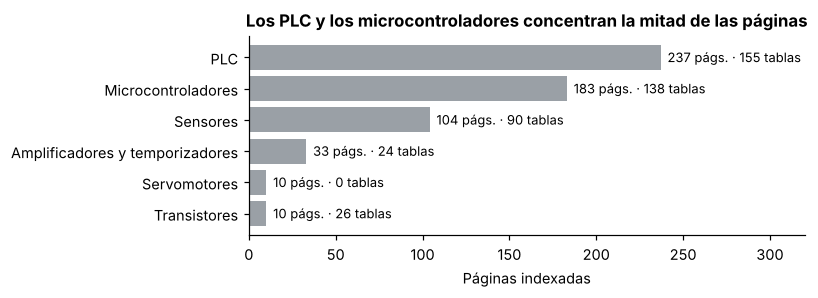

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 2.8))
datos = resumen.drop("Total").sort_values("paginas_indexadas")
ax.barh(datos.index, datos["paginas_indexadas"], color=GRIS)
for y, (p, t) in enumerate(zip(datos["paginas_indexadas"], datos["tablas"])):
    ax.text(p + 4, y, f"{p} págs. · {t} tablas", va="center", fontsize=8.5)
ax.set_title("Los PLC y los microcontroladores concentran la mitad de las páginas")
ax.set_xlabel("Páginas indexadas"); ax.set_xlim(0, datos["paginas_indexadas"].max() * 1.35)
plt.tight_layout(); plt.show()

### 3.2 Representación: extracción

**Extracción con PyMuPDF (D3–D8).** Se usan dos modos, que se comparan en los experimentos:

| Modo | Representación | Uso |
|---|---|---|
| `simple` | Texto plano en orden de lectura | Línea base |
| `tablas` | Texto + cada tabla convertida a Markdown (filas y columnas explícitas) | Configuración final |

**Limpieza:**
- Se eliminan los encabezados y pies repetidos, solo en los márgenes de la página.
- El texto que cae dentro de una tabla se conserva si la tabla no lo capturó: menos del 80 %
  de sus palabras está cubierto (D8).
- Las celdas combinadas no se rellenan, para no inventar valores (D5).

### 3.3 Representación: fragmentación (chunking)

**Fragmentos (D10, D13, D22):**
- Cada fragmento tiene 150 palabras, con un solapamiento del 15 %, y no cruza de página.
- Lleva el encabezado `[nombre — doc_id, pág. N]`.
- Cuando una tabla se parte, cada parte repite el título y la fila de encabezados de la tabla
  (D22). Sin eso, una fila de la tabla de termocuplas llega al modelo sin saber qué columna
  es qué.

**Por qué 150 palabras:** el modelo de embeddings corta la entrada en 512 tokens. La celda
siguiente mide cuántos fragmentos se truncarían con cada tamaño.

In [4]:
if HAY_BASE:
    from transformers import AutoTokenizer
    from rag.chunking import fragmentar
    tok = AutoTokenizer.from_pretrained(config.MODELO_EMBEDDINGS)
    filas = []
    for tam in (150, 300):
        chunks = fragmentar("tablas", tam)
        largos = [len(tok("passage: " + c.texto_indexado)["input_ids"]) for c in chunks]
        filas.append({"palabras por fragmento": tam, "fragmentos": len(chunks),
                      "truncados (>512 tokens)": sum(l > 512 for l in largos),
                      "% truncados": round(100 * sum(l > 512 for l in largos) / len(largos), 1)})
    display(pd.DataFrame(filas))
else:
    print("Requiere la base de conocimiento. Con el chunking final: 16,5 % de fragmentos truncados "
          "con 150 palabras frente a 40,9 % con 300.")

,palabras por fragmento,fragmentos,truncados (>512 tokens),% truncados
0,150,1690,279,16.5
1,300,872,357,40.9


Con 300 palabras se truncaría el 41 % de los fragmentos: el modelo de embeddings no vería
el final de casi la mitad de las tablas. Con 150 palabras se trunca el 16,5 %.

En la versión v1 (sin repetir título ni encabezado de tabla) la cifra era 11 % frente a
39 % (D13). El contexto de tablas (D22) alarga algunos fragmentos, pero es un costo
aceptable: mejora las respuestas sobre tablas (§6.2).

In [5]:
if HAY_BASE:
    chunks = fragmentar("tablas", 150)
    ejemplo = next(c for c in chunks if c.doc_id == "termocuplas_ref" and c.pagina == 22 and "|120|" in c.texto)
    print(f"Fragmento {ejemplo.chunk_id} · {ejemplo.n_palabras} palabras\n")
    print(ejemplo.texto_indexado[:1200])
else:
    print("Requiere la base de conocimiento.")

Fragmento termocuplas_ref|p22|1 · 145 palabras

[Datos de referencia de termopares y Pt100 (IEC 584 / IEC 751) — termocuplas_ref, pág. 22]
Type K Thermocouple Table
Nickel-Chromium/Nickel-Aluminium, Electromotive force as a function of temperature

| | | | | |E/µV| | | | | | |
|---|---|---|---|---|---|---|---|---|---|---|---|
|t90/°C|0|1|2|3|4|5|6|7|8|9|t90/°C|
|90|3682|3723|3765|3806|3848|3889|3931|3972|4013|4055|90|
|100|4096|4138|4179|4220|4262|4303|4344|4385|4427|4468|100|
|110|4509|4550|4591|4633|4674|4715|4756|4797|4838|4879|110|
|120|4920|4961|5002|5043|5084|5124|5165|5206|5247|5288|120|
|130|5328|5369|5410|5450|5491|5532|5572|5613|5653|5694|130|
|140|5735|5775|5815|5856|5896|5937|5977|6017|6058|6098|140|
|150|6138|6179|6219|6259|6299|6340|6380|6420|6460|6500|150|
|160|6540|6580|6620|6660|6701|6741|6781|6821|6861|6901|160|
|170|6941|6981|7021|7060|7100|7140|7180|7220|7260|7300|170|


El fragmento anterior es la parte de la tabla de termocuplas tipo K que contiene la fila de
120 °C. Gracias a D22, empieza con el título de la tabla y la fila de encabezados (0 a 9), así
que el modelo puede leer la celda correcta (fila 120, columna 5 → 125 °C).

### 3.4 Restricciones de datos y cómputo

| Restricción | Consecuencia en el diseño |
|---|---|
| PC sin GPU, 8 GB de RAM | Embeddings y reordenador pequeños (~118 M parámetros cada uno) en CPU; búsqueda exacta con NumPy (1690 vectores) |
| Presupuesto cero | LLM por API gratuita: Gemma 4 31B. La cuota de gemini-3.5-flash es de unas 20 solicitudes al día (D17) |
| Preguntas en español, 17 de 23 documentos en inglés | Modelos multilingües (mE5, mMARCO) |
| La base crece | Extracción e índice incrementales (D24) |

## 4. Diseño e implementación (E3)

### 4.1 Arquitectura

El sistema tiene dos flujos:
- **Indexación:** se hace una vez por documento.
- **Consulta:** se repite con cada pregunta.

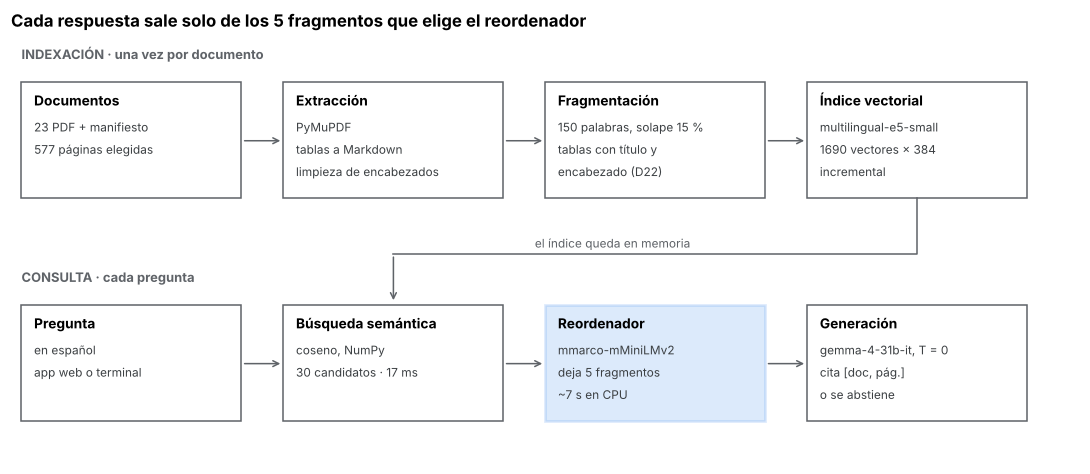

In [6]:
def caja(ax, x, y, titulo, lineas, acento=False):
    ax.add_patch(plt.Rectangle((x, y), 2.1, 1.25, fill=acento, alpha=0.15 if acento else 1,
                               ec=ACENTO if acento else "#5f6368", lw=1.8 if acento else 1, fc=ACENTO if acento else "none"))
    ax.text(x + 0.12, y + 1.0, titulo, fontweight="bold", fontsize=9)
    for i, l in enumerate(lineas):
        ax.text(x + 0.12, y + 0.72 - i * 0.24, l, fontsize=7.8, color="#3c4043")

fig, ax = plt.subplots(figsize=(10, 4.4)); ax.set_xlim(0, 10.2); ax.set_ylim(0, 4.6); ax.axis("off")
ax.text(0.1, 4.35, "INDEXACIÓN · una vez por documento", fontsize=8.5, color="#5f6368", fontweight="bold")
ax.text(0.1, 1.95, "CONSULTA · cada pregunta", fontsize=8.5, color="#5f6368", fontweight="bold")
xs = [0.1, 2.6, 5.1, 7.6]
for x, (t, l) in zip(xs, [("Documentos", ["23 PDF + manifiesto", "577 páginas elegidas"]),
                          ("Extracción", ["PyMuPDF", "tablas a Markdown", "limpieza de encabezados"]),
                          ("Fragmentación", ["150 palabras, solape 15 %", "tablas con título y", "encabezado (D22)"]),
                          ("Índice vectorial", ["multilingual-e5-small", "1690 vectores × 384", "incremental"])]):
    caja(ax, x, 2.85, t, l)
for x, (t, l, a) in zip(xs, [("Pregunta", ["en español", "app web o terminal"], False),
                             ("Búsqueda semántica", ["coseno, NumPy", "30 candidatos · 17 ms"], False),
                             ("Reordenador", ["mmarco-mMiniLMv2", "deja 5 fragmentos", "~7 s en CPU"], True),
                             ("Generación", ["gemma-4-31b-it, T = 0", "cita [doc, pág.]", "o se abstiene"], False)]):
    caja(ax, x, 0.45, t, l, a)
for y in (3.47, 1.07):
    for x in xs[:-1]:
        ax.annotate("", (x + 2.5, y), (x + 2.1, y), arrowprops=dict(arrowstyle="->", color="#5f6368"))
ax.plot([8.65, 8.65, 3.65], [2.85, 2.25, 2.25], color="#5f6368", lw=1)
ax.annotate("", (3.65, 1.72), (3.65, 2.25), arrowprops=dict(arrowstyle="->", color="#5f6368"))
ax.text(5.0, 2.32, "el índice queda en memoria", fontsize=7.8, color="#5f6368")
ax.set_title("Cada respuesta sale solo de los 5 fragmentos que elige el reordenador", loc="left")
plt.tight_layout(); plt.show()

### 4.2 Implementación

El código es un paquete de Python modular. Cada etapa guarda archivos intermedios, lo que
permite reproducir y comparar variantes sin rehacer todo (D7).

| Módulo | Responsabilidad |
|---|---|
| `rag/manifiesto.py` | Carga y valida el manifiesto del corpus |
| `rag/extraccion.py` | PyMuPDF, tablas a Markdown, limpieza, caché incremental por huella SHA-256 |
| `rag/chunking.py` | Fragmentación por página con contexto de tablas |
| `rag/busqueda.py` | Índice: BM25, semántica, híbrida RRF y reordenamiento; embeddings incrementales |
| `rag/llm.py` | Cliente de Gemini con caché en disco, reintentos y límite de ritmo por clave |
| `rag/asistente.py` | Arma el contexto, instrucciones de cita y abstención, modelos de respaldo |
| `rag/juez.py`, `rag/metricas.py` | Evaluación (LLM como juez y métricas de recuperación) |
| `01_extraer.py` … `05_graficas.py` | Pipeline y experimentos reproducibles |
| `web/app.py`, `preguntar.py`, `agregar_documento.py` | App web, terminal y alimentación continua |

La configuración final y las instrucciones que recibe el modelo:

In [7]:
from rag.asistente import SISTEMA_RAG
parametros = {k: getattr(config, k) for k in ["MODO_DEFECTO", "TAMANO_CHUNK", "SOLAPAMIENTO", "CONTEXTO_TABLAS",
              "MODELO_EMBEDDINGS", "METODO_DEFECTO", "MODELO_RERANK", "CANDIDATOS_RERANK", "K_CONTEXTO",
              "MODELO_LLM", "MODELOS_RESPALDO", "MODELO_JUEZ"]}
display(pd.DataFrame(parametros.items(), columns=["parámetro", "valor"]))
print(SISTEMA_RAG)

,parámetro,valor
0,MODO_DEFECTO,tablas
1,TAMANO_CHUNK,150
2,SOLAPAMIENTO,0.15
3,CONTEXTO_TABLAS,True
4,MODELO_EMBEDDINGS,intfloat/multilingual-e5-small
5,METODO_DEFECTO,semantica_rerank
6,MODELO_RERANK,cross-encoder/mmarco-mMiniLMv2-L12-H384-v1
7,CANDIDATOS_RERANK,30
8,K_CONTEXTO,5
9,MODELO_LLM,gemma-4-31b-it


Eres un asistente técnico para estudiantes e ingenieros de mecatrónica.
Respondes preguntas sobre datasheets y manuales usando ÚNICAMENTE los fragmentos de
documentación que se te entregan.

Reglas:
1. Usa solo la información de los fragmentos. No completes con conocimiento propio.
2. Cita cada dato con el formato [doc_id, pág. N], usando el doc_id y la página que
   aparecen en el encabezado del fragmento.
3. Indica siempre a qué dispositivo o variante corresponde cada valor (por ejemplo,
   LM324 frente a LM2902) y conserva las unidades y condiciones de medida.
4. Si la pregunta es ambigua porque puede referirse a varios componentes de los
   fragmentos, dilo explícitamente, da el dato de cada uno y pide que se precise.
5. Si los fragmentos no contienen la respuesta, empieza tu respuesta exactamente con:
   "No encuentro esa información en la documentación disponible." y no inventes valores, aunque haya un componente parecido.
6. Si dos fuentes se contradicen, señálalo.
7. Responde e

### 4.3 Demostración: qué aporta el reordenador

La misma pregunta, con búsqueda semántica sola y con reordenamiento. La evidencia verificada a
mano está en `termocuplas_ref`, página 22.

In [8]:
PREGUNTA = "¿Qué fuerza electromotriz genera un termopar tipo K a 125 °C?"
if HAY_BASE:
    from rag.busqueda import Indice
    indice = Indice(config.MODO_DEFECTO, config.TAMANO_CHUNK).construir()
    filas = []
    for metodo in ("semantica", "semantica_rerank"):
        for r in indice.buscar(PREGUNTA, k=5, metodo=metodo):
            filas.append({"método": metodo, "rango": r.rango, "documento": r.chunk.doc_id, "página": r.chunk.pagina,
                          "puntaje": round(r.puntaje, 3),
                          "¿evidencia?": "✔" if (r.chunk.doc_id, r.chunk.pagina) == ("termocuplas_ref", 22) else ""})
    display(pd.DataFrame(filas).set_index(["método", "rango"]))
else:
    print("Requiere la base de conocimiento.")

documento  página  puntaje ¿evidencia?
método           rango                                              
semantica        1      termocuplas_ref      32    0.873            
                 2      termocuplas_ref      28    0.872            
                 3      termocuplas_ref      28    0.870            
                 4      termocuplas_ref      28    0.869            
                 5      termocuplas_ref      28    0.869            
semantica_rerank 1      termocuplas_ref      23    2.446            
                 2      termocuplas_ref      22    2.143           ✔
                 3      termocuplas_ref      22    2.090           ✔
                 4      termocuplas_ref      23    2.079            
                 5      termocuplas_ref      22    1.918           ✔

In [9]:
if HAY_BASE and HAY_CLAVE:
    from rag.asistente import responder
    r = responder(PREGUNTA, indice)
    print(f"Modelo: {r.llm.modelo} · respuesta guardada en caché: {r.llm.desde_cache}\n")
    print(r.texto)
    print("\nCitas:", r.citas)
else:
    print("Requiere la base de conocimiento y una clave de Gemini.")

Modelo: gemma-4-31b-it · respuesta guardada en caché: True

Un termopar tipo K a 125 °C genera una fuerza electromotriz de 5124 µV [termocuplas_ref, pág. 22].

Citas: [('termocuplas_ref', 22)]


La respuesta correcta, verificada en el PDF, es **5124 µV** (tabla tipo K, fila 120 °C, columna 5).

### 4.4 Decisiones técnicas frente a las restricciones

| Decisión | Alternativas medidas | Por qué |
|---|---|---|
| Modo `tablas` | `simple` | Mejor recuperación (hit@5 0,60 frente a 0,53) |
| 150 palabras | 300, 600 | Menos truncamiento y mejor recuperación (ver §5.2) |
| multilingual-e5-small | e5-base | Corre en CPU con 8 GB; consultas en 17 ms |
| Reordenador mmarco-mMiniLMv2 | bge-reranker-v2-m3 | El grande tardaba ~78 s por consulta en CPU; el elegido ~7 s |
| Gemma 4 31B | gemini-3.5-flash | Cuota gratuita amplia; flash queda como respaldo |
| K = 5 fragmentos | — | ~2000 tokens de contexto; menos ruido (*Lost in the Middle*) |

### 4.5 Implicaciones éticas, de privacidad y de sesgo

- **Seguridad del usuario:** un valor técnico inventado puede dañar equipos. Por eso el
  sistema debe citar cada dato y abstenerse con una frase fija cuando no lo encuentra; con RAG
  se abstuvo correctamente en las 6 preguntas sin respuesta.
- **Derechos de autor:** los PDF y el texto extraído están en un repositorio privado; el código es público.
- **Privacidad:** en la app web cada usuario usa su propia clave de Gemini, que no se guarda
  en disco ni en los registros (D25).
- **Sesgos de la evaluación:**
  - Las preguntas las redactó el mismo equipo que diseñó el sistema, aunque cada respuesta de
    referencia se tomó del PDF.
  - El juez LLM tiene sesgos conocidos (Zheng et al., 2023); por eso se auditó a mano y las
    abstenciones se califican por regla (§6.3).
- **Dependencia de terceros:** la generación depende de la API de Google y de su cuota gratuita.

## 5. Diseño de experimentos y resultados (E4)

### 5.1 Diseño

RAG no entrena un modelo, así que no hay partición entrenamiento/validación. En su lugar se
usa un **conjunto de prueba controlado**: 66 preguntas escritas a partir de los PDF, cada una
con su respuesta de referencia y la página de evidencia verificadas a mano (D9). El sistema
nunca se ajustó con estas preguntas.

- **Tipos de pregunta:**
  - datos puntuales y lecturas de tablas;
  - comparaciones entre dispositivos o documentos;
  - preguntas ambiguas y con contradicciones;
  - 6 preguntas **sin respuesta en el corpus**, para medir la abstención.
- **Dos niveles de evaluación:**
  1. **Recuperación (sin LLM):** hit@k, que indica si la página de evidencia está entre los k
     primeros fragmentos; doc@k, si lo está el documento correcto; y MRR.
  2. **Respuesta final:** un juez LLM (gemini-3.5-flash-lite, distinto del generador) califica
     corrección, fidelidad al contexto, alucinación y comportamiento. Las abstenciones se
     califican por regla y la calidad de la cita se mide automáticamente.
- **Ablaciones y línea base:** se cambia una pieza a la vez frente al sistema final y se
  compara contra el mismo modelo **sin RAG**.
- **Estadística:**
  - Intervalos de confianza del 95 % por bootstrap (10 000 remuestreos).
  - Prueba de signos pareada sobre las preguntas en que dos configuraciones difieren.

In [10]:
preguntas = pd.read_csv("evaluacion/preguntas.csv")
display(preguntas.groupby(["tipo", "comportamiento"]).size().rename("preguntas").reset_index()
        .sort_values("preguntas", ascending=False).reset_index(drop=True))
display(preguntas[["id", "tipo", "pregunta", "respuesta_referencia", "evidencia"]].sample(4, random_state=1))

,tipo,comportamiento,preguntas
0,dato,responder,26
1,tabla,responder,15
2,multidispositivo,responder,6
3,sin_respuesta,no_sabe,6
4,confusor,responder,4
5,multi_doc,responder,4
6,ambigua,pedir_aclaracion,2
7,procedimiento,responder,2
8,contradiccion,responder,1


,id,tipo,pregunta,respuesta_referencia,evidencia
46,srv07,multi_doc,¿Qué servo tiene más torque a 6 V: el MG90S o el MG996R?,"El MG996R: 11 kgf·cm frente a 2,2 kgf·cm del MG90S.",mg996r:1;mg90s:1
57,amp05,multidispositivo,¿Cuál es el voltaje de offset de entrada máximo del LM324 a 25 °C?,7 mV (típico 3 mV) para el LM324 estándar; la versión LM324B tiene un máximo de 3 mV.,lm324:11;lm324:1
47,tr01,dato,"¿Cuáles son la tensión, la corriente y la resistencia de encendido del IRF540N?","V(BR)DSS de 100 V, ID de 33 A (a 25 °C) y RDS(on) máxima de 44 mΩ con VGS = 10 V.",irf540n:1;irf540n:2
2,mc03,dato,¿En qué rango de voltaje de alimentación opera el ESP32?,"De 2,3 V a 3,6 V.",esp32:19


### 5.2 Recuperación

Todos los métodos y tamaños se evaluaron sobre las 60 preguntas con respuesta.

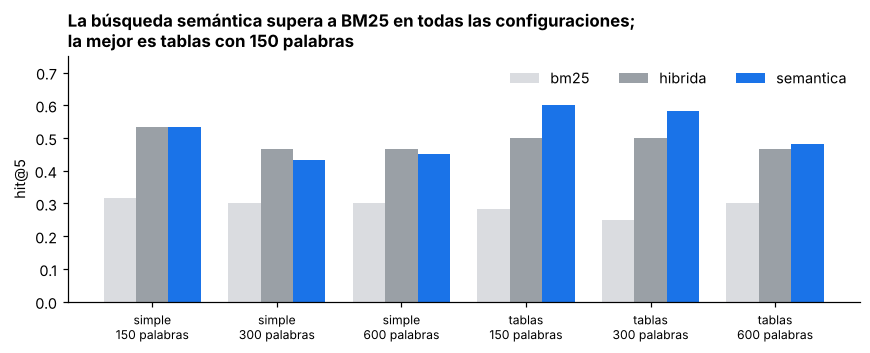

In [11]:
rec = pd.read_csv("reportes/recuperacion_resumen.csv")
rec["configuración"] = rec["modo"] + "\n" + rec["tamano"].astype(str) + " palabras"
tabla = rec.pivot(index="configuración", columns="metodo", values="hit@5")[["bm25", "hibrida", "semantica"]]

fig, ax = plt.subplots(figsize=(8, 3.3))
ancho = 0.26
for i, (m, color) in enumerate(zip(tabla.columns, ["#dadce0", "#9aa0a6", ACENTO])):
    xs = [j + (i - 1) * ancho for j in range(len(tabla))]
    ax.bar(xs, tabla[m], ancho, color=color, label=m)
ax.set_xticks(range(len(tabla))); ax.set_xticklabels(tabla.index, fontsize=8)
ax.set_ylabel("hit@5"); ax.set_ylim(0, 0.75); ax.legend(frameon=False, ncols=3, loc="upper right")
ax.set_title("La búsqueda semántica supera a BM25 en todas las configuraciones;\nla mejor es tablas con 150 palabras", loc="left")
plt.tight_layout(); plt.show()

In [12]:
r1 = pd.read_csv("reportes/recuperacion_resumen_rerank.csv").assign(chunking="v1")
r2 = pd.read_csv("reportes/recuperacion_resumen_v2.csv").assign(chunking="v2 (D22, final)")
base = rec[(rec["modo"] == "tablas") & (rec["tamano"] == 150)].assign(chunking="v1")
todo = pd.concat([base, r1[r1["metodo"] != "semantica"], r2])
cols = ["chunking", "metodo", "hit@1", "hit@5", "doc@5", "mrr"]
todo[cols].sort_values(["chunking", "mrr"]).reset_index(drop=True)

,chunking,metodo,hit@1,hit@5,doc@5,mrr
0,v1,bm25,0.117,0.283,0.467,0.191
1,v1,hibrida,0.200,0.500,0.883,0.330
2,v1,semantica,0.267,0.600,0.950,0.404
3,v1,hibrida_rerank,0.550,0.783,0.950,0.641
4,v1,semantica_rerank,0.583,0.817,0.950,0.691
5,"v2 (D22, final)",semantica,0.283,0.533,0.950,0.406
6,"v2 (D22, final)",semantica_rerank,0.533,0.767,0.950,0.653


- El reordenador **duplica hit@1** (0,27 → 0,58) y sube el MRR de 0,40 a 0,69.
- doc@5 = 0,95 en todos los métodos densos: la búsqueda casi siempre encuentra el documento
  correcto. El problema era ordenar las páginas dentro del documento, y eso es lo que corrige
  el reordenador.
- BM25 falla porque las preguntas están en español y la mayoría de los documentos en inglés;
  en la híbrida, ese ruido empeora a la semántica.
- Con el chunking v2, hit@5 baja de 0,82 a 0,77, pero las respuestas mejoran (§5.3). La
  métrica de recuperación por página no basta para elegir el chunking.

### 5.3 Calidad de las respuestas

Se calculan desde las 66 respuestas calificadas de cada configuración
(`reportes/respuestas_detalle*.csv`).

In [13]:
import math, random
det = pd.read_csv("reportes/respuestas_detalle.csv")
det_v2 = pd.read_csv("reportes/respuestas_detalle_d22.csv")
det = pd.concat([det.replace({"config": {"rag_final": "rag_final_v1"}}),
                 det_v2[det_v2["config"] == "rag_final"].replace({"config": {"rag_final": "rag_final_v2"}})])
NOMBRES = {"rag_final_v2": "RAG final v2 (D22)", "rag_final_simple": "RAG v1, extracción simple",
           "rag_final_v1": "RAG final v1", "rag_sin_rerank": "RAG sin reordenador",
           "sin_rag": "Sin RAG (línea base)", "rag_bm25": "RAG con BM25"}

def num(serie):
    return pd.to_numeric(serie.replace({"True": 1, "False": 0, True: 1, False: 0}), errors="coerce")

def resumen_config(g):
    resp = g[g["comportamiento"] == "responder"]
    nosabe = g[g["comportamiento"] == "no_sabe"]
    return pd.Series({
        "corrección": num(g["correccion"]).mean(),
        "comportamiento esperado": num(g["comportamiento_ok"]).mean(),
        "alucinación": num(g["alucinacion"]).mean(),
        "abstención correcta (n=6)": num(nosabe["se_abstiene"]).mean(),
        "abstención indebida": num(resp["se_abstiene"]).mean(),
        "cita correcta": num(g["cita_correcta"]).mean()})

tabla_resp = det.groupby("config").apply(resumen_config).rename(index=NOMBRES)
tabla_resp.sort_values("corrección", ascending=False).round(3)

,corrección,comportamiento esperado,alucinación,abstención correcta (n=6),abstención indebida,cita correcta
config,,,,,,
"RAG v1, extracción simple",0.833,0.803,0.000,1.0,0.155,0.843
RAG final v2 (D22),0.833,0.818,0.015,1.0,0.155,0.800
RAG final v1,0.795,0.788,0.015,1.0,0.155,0.816
RAG sin reordenador,0.629,0.636,0.000,1.0,0.328,0.619
Sin RAG (línea base),0.576,0.742,0.212,0.0,0.069,NaN
RAG con BM25,0.364,0.364,0.000,1.0,0.690,0.737


In [14]:
random.seed(2026)
def bootstrap_ic(valores, B=10_000):
    n = len(valores)
    medias = sorted(sum(random.choices(valores, k=n)) / n for _ in range(B))
    return medias[int(0.025 * B)], medias[int(0.975 * B) - 1]

def prueba_signos(mejor, peor):
    n, k = mejor + peor, min(mejor, peor)
    return 1.0 if n == 0 else min(1.0, 2 * sum(math.comb(n, i) for i in range(k + 1)) / 2 ** n)

corr = det.assign(c=num(det["correccion"])).pivot(index="id", columns="config", values="c")
ic = pd.DataFrame({cfg: {"corrección": corr[cfg].mean(), **dict(zip(["IC95 inf", "IC95 sup"], bootstrap_ic(list(corr[cfg]))))}
                   for cfg in corr}).T

def comparar(a, b):
    d = (corr[a] - corr[b]).dropna()
    lo, hi = bootstrap_ic(list(d))
    return {"comparación": f"{NOMBRES[a]} vs {NOMBRES[b]}", "diferencia": d.mean(), "IC95 inf": lo, "IC95 sup": hi,
            "mejor / peor": f"{(d > 0).sum()} / {(d < 0).sum()}", "p (signos)": prueba_signos((d > 0).sum(), (d < 0).sum())}

pares = [("rag_final_v2", "sin_rag"), ("rag_final_v1", "sin_rag"), ("rag_final_v1", "rag_sin_rerank"),
         ("rag_final_v1", "rag_bm25"), ("rag_final_simple", "rag_final_v1"), ("rag_final_v2", "rag_final_v1")]
display(pd.DataFrame([comparar(a, b) for a, b in pares]).round(3))

,comparación,diferencia,IC95 inf,IC95 sup,mejor / peor,p (signos)
0,RAG final v2 (D22) vs Sin RAG (línea base),0.258,0.114,0.402,28 / 9,0.003
1,RAG final v1 vs Sin RAG (línea base),0.220,0.068,0.371,27 / 11,0.014
2,RAG final v1 vs RAG sin reordenador,0.167,0.068,0.265,17 / 4,0.007
3,RAG final v1 vs RAG con BM25,0.432,0.318,0.553,31 / 1,0.000
4,"RAG v1, extracción simple vs RAG final v1",0.038,-0.030,0.114,5 / 3,0.727
5,RAG final v2 (D22) vs RAG final v1,0.038,-0.008,0.098,3 / 1,0.625


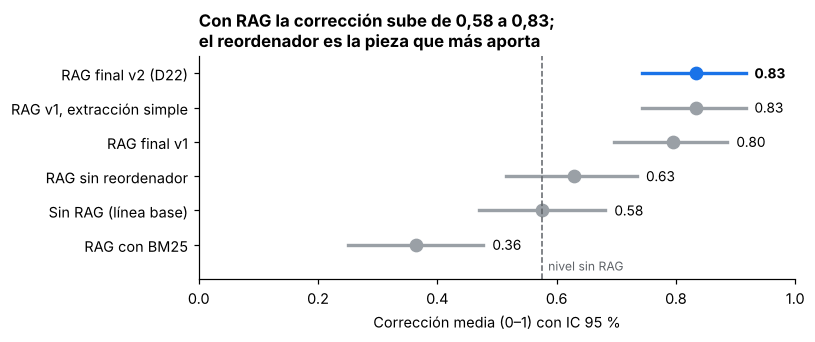

In [15]:
orden = ["rag_bm25", "sin_rag", "rag_sin_rerank", "rag_final_v1", "rag_final_simple", "rag_final_v2"]
fig, ax = plt.subplots(figsize=(7.5, 3.2))
for y, cfg in enumerate(orden):
    m, lo, hi = ic.loc[cfg, "corrección"], ic.loc[cfg, "IC95 inf"], ic.loc[cfg, "IC95 sup"]
    color = ACENTO if cfg == "rag_final_v2" else GRIS
    ax.plot([lo, hi], [y, y], color=color, lw=2.2); ax.plot(m, y, "o", color=color, ms=8)
    ax.text(hi + 0.015, y, f"{m:.2f}", va="center", fontsize=9, fontweight="bold" if color == ACENTO else None)
ax.axvline(ic.loc["sin_rag", "corrección"], ls="--", color="#5f6368", lw=1)
ax.text(ic.loc["sin_rag", "corrección"] + 0.01, -0.75, "nivel sin RAG", fontsize=8, color="#5f6368")
ax.set_ylim(-1, len(orden) - 0.5)
ax.set_yticks(range(len(orden))); ax.set_yticklabels([NOMBRES[c] for c in orden])
ax.set_xlim(0, 1); ax.set_xlabel("Corrección media (0–1) con IC 95 %")
ax.set_title("Con RAG la corrección sube de 0,58 a 0,83;\nel reordenador es la pieza que más aporta", loc="left")
plt.tight_layout(); plt.show()

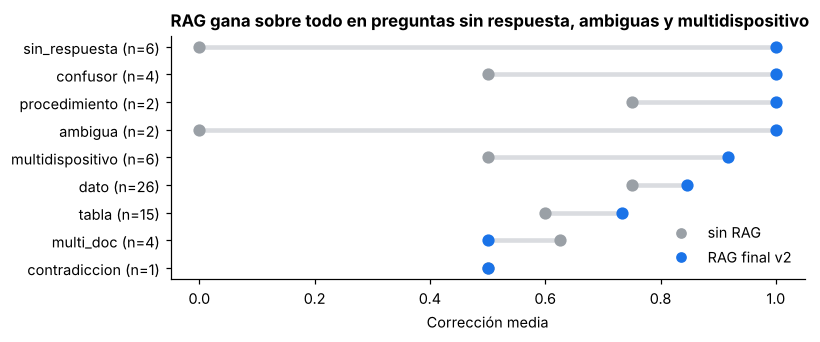

In [16]:
por_tipo = (det[det["config"].isin(["sin_rag", "rag_final_v2"])]
            .assign(c=lambda d: num(d["correccion"]))
            .pivot_table(index="tipo", columns="config", values="c", aggfunc="mean"))
por_tipo["n"] = preguntas.groupby("tipo").size()
por_tipo = por_tipo.sort_values("rag_final_v2")
fig, ax = plt.subplots(figsize=(7.5, 3.2))
for y, (tipo, f) in enumerate(por_tipo.iterrows()):
    ax.plot([f["sin_rag"], f["rag_final_v2"]], [y, y], color="#dadce0", lw=3, zorder=1)
    ax.plot(f["sin_rag"], y, "o", color=GRIS, ms=7, zorder=2)
    ax.plot(f["rag_final_v2"], y, "o", color=ACENTO, ms=7, zorder=2)
ax.set_yticks(range(len(por_tipo))); ax.set_yticklabels([f"{t} (n={int(n)})" for t, n in zip(por_tipo.index, por_tipo["n"])])
ax.set_xlim(-0.05, 1.05); ax.set_xlabel("Corrección media")
ax.plot([], [], "o", color=GRIS, label="sin RAG"); ax.plot([], [], "o", color=ACENTO, label="RAG final v2")
ax.legend(frameon=False, loc="lower right")
ax.set_title("RAG gana sobre todo en preguntas sin respuesta, ambiguas y multidispositivo", loc="left")
plt.tight_layout(); plt.show()

**Resultados principales:**
1. **El RAG mejora la corrección de forma significativa**, de 0,58 a 0,83 (+0,26; IC 95 %
   [0,11; 0,40]; p = 0,003), y **casi elimina las alucinaciones**: 21 % frente a 2 %.
2. **El reordenador es el componente que más aporta:** +0,17 (p = 0,007). Con BM25 el RAG
   queda incluso por debajo de no usar RAG, porque se abstiene de más.
3. **La extracción `simple` y la `tablas` v1 no difieren de forma significativa** (p = 0,73).
   El contexto de tablas (v2) mejora las preguntas de tabla de 0,57 a 0,73, aunque sobre el
   total no es significativo (+0,04).
4. **Dónde no gana:** en las preguntas multidocumento acierta 0,50 frente a 0,62 sin RAG (n = 4).
5. **Grupos pequeños:** varios tipos tienen de 1 a 6 preguntas, así que las diferencias por
   tipo son orientativas.

## 6. Análisis de errores, limitaciones y conclusiones (E5)

### 6.1 Errores del sistema final

Las respuestas imperfectas de la configuración final (corrección < 1):

In [17]:
v2 = det[det["config"] == "rag_final_v2"].assign(c=lambda d: num(d["correccion"]))
errores = v2[v2["c"] < 1][["id", "tipo", "c", "pregunta", "justificacion"]].sort_values("c")
errores["justificacion"] = errores["justificacion"].str.slice(0, 150) + "…"
print(f"{len(errores)} de {len(v2)} respuestas imperfectas")
errores.rename(columns={"c": "corrección"}).reset_index(drop=True)

13 de 66 respuestas imperfectas


,id,tipo,corrección,pregunta,justificacion
0,mc04,tabla,0.0,¿Cuánta corriente puede entregar y absorber un pin GPIO del ESP32?,"El asistente indicó que no encontraba la información, pero el comportamiento esperado era responder con el dato corr..."
1,mc07,dato,0.0,¿Los pines del STM32F767 toleran 5 V?,El asistente indicó que no encontraba la información a pesar de que la pregunta requería respuesta.…
2,mc08,tabla,0.0,¿Cuál es la corriente máxima que puede absorber o entregar un pin de E/S del STM32F767?,El asistente indicó que no encontró la información cuando el comportamiento esperado era responder con el dato corre...
3,sen09,tabla,0.0,¿Qué resistencia tiene el termistor NTCLE100E3103 a 100 °C?,"El comportamiento esperado era responder con el dato, pero el asistente indicó que no encontraba la información a pe..."
4,tr01,dato,0.0,"¿Cuáles son la tensión, la corriente y la resistencia de encendido del IRF540N?","El asistente indicó correctamente que no encontraba la información, ya que los fragmentos proporcionados no contenía..."
5,srv06,dato,0.0,¿Cuál es el periodo de la señal de control del SG90?,"El asistente indicó correctamente que no tenía la información en los fragmentos, coincidiendo con el comportamiento ..."
6,tr04,multi_doc,0.0,¿Qué MOSFET del corpus se puede manejar directamente con los 5 V de un microcontrolador?,El asistente respondió que no encontraba la información cuando se esperaba que respondiera con el dato correcto del ...
7,tr03,multi_doc,0.0,¿En qué se diferencia la tensión umbral de compuerta del IRFZ44N y la del IRLZ44N?,"El asistente indicó que no encontraba la información, pero el comportamiento esperado era responder con los datos co..."
8,tr05,dato,0.0,¿Cuáles son los valores principales del IRF4905?,El asistente indicó correctamente que no sabía la respuesta porque la información no está en los fragmentos.…
9,sen08,tabla,0.5,¿Qué resistencia tiene el termistor NTC NTCLE100E3103 (10 kΩ) a 0 °C?,El asistente da un dato aproximado pero no el valor exacto de 32 554 Ω que está en otra parte de la hoja de datos.…


**Taxonomía de errores** (análisis del sistema v1, `RESULTADOS.md` §4; 15 respuestas
imperfectas de 66):

| Origen | n | Mecanismo |
|---|---|---|
| La búsqueda no trajo la página | 8 | Tablas de características muy parecidas dentro de un mismo documento (corriente de GPIO, *Absolute Maximum Ratings*); una pregunta exige cruzar varios documentos |
| La tabla se partió y perdió su contexto | 3 | El fragmento con el valor llegaba sin el título ni la fila de encabezados → **corregido con D22** |
| El modelo no usó bien el contexto | 4 | Abstención con el dato presente; no señaló una contradicción entre páginas (120° frente a 180° del MG996R); celdas combinadas vacías (LM124); una respuesta vacía |

### 6.2 Mejora verificada: contexto de tablas (D22)

In [18]:
cambio = (corr["rag_final_v2"] - corr["rag_final_v1"]).rename("v2 − v1")
cambios = pd.concat([corr[["rag_final_v1", "rag_final_v2"]], cambio], axis=1)[cambio != 0]
cambios = cambios.join(preguntas.set_index("id")[["tipo", "pregunta"]])
cambios.sort_values("v2 − v1", ascending=False)

,rag_final_v1,rag_final_v2,v2 − v1,tipo,pregunta
id,,,,,
sen11,0.0,1.0,1.0,tabla,¿Qué fuerza electromotriz genera un termopar tipo K a 100 °C?
sen12,0.0,1.0,1.0,tabla,¿Qué fuerza electromotriz genera un termopar tipo K a 125 °C?
sen13,0.0,1.0,1.0,tabla,¿Qué fuerza electromotriz genera un termopar tipo J a 100 °C?
sen08,1.0,0.5,-0.5,tabla,¿Qué resistencia tiene el termistor NTC NTCLE100E3103 (10 kΩ) a 0 °C?


Las preguntas que mejoran son búsquedas en las tablas de termocuplas, incluida una de doble
entrada: tipo K a 125 °C = 5124 µV, fila 120 y columna 5. Esto confirma el mecanismo
identificado en §6.1.

### 6.3 Validez de la evaluación

- **Sesgo del juez detectado y corregido:**
  - El juez premiaba abstenciones en preguntas que sí tenían respuesta.
  - Como la frase de abstención es fija, se califican por regla (D20). Sin esa corrección,
    BM25 aparecía con 0,65 en vez de 0,36.
- **Auditoría manual:**
  - En 24 respuestas al azar, el juez coincidió con la revisión humana en 22 (92 %).
  - En los 2 desacuerdos el juez fue 0,5 más indulgente, así que las cifras absolutas pueden
    estar levemente infladas.
  - La comparación entre configuraciones no se ve afectada.
- **Tamaño de muestra:** con 66 preguntas solo son concluyentes las diferencias grandes;
  por eso se reportan intervalos y pruebas pareadas.

### 6.4 Ejemplos cualitativos: alucinación sin RAG

In [19]:
for pid in ["nr04", "nr01"]:
    if pid not in set(det["id"]):
        continue
    fila = det[(det["id"] == pid)]
    print(f"■ {fila['pregunta'].iloc[0]}")
    for cfg in ["sin_rag", "rag_final_v2"]:
        texto = str(fila[fila["config"] == cfg]["respuesta"].iloc[0]).replace("\n", " ")
        print(f"  {NOMBRES[cfg]}: {texto[:260]}{'…' if len(texto) > 260 else ''}")
    print()

■ ¿Cuál es el torque del servo MG995?
  Sin RAG (línea base): El torque del servo MG995 es: * **4.8V:** 9.4 kg-cm * **6.0V:** 11 kg-cm
  RAG final v2 (D22): No encuentro esa información en la documentación disponible.

■ ¿Cuánta corriente consume el ESP32-S3 en modo deep-sleep?
  Sin RAG (línea base): El ESP32-S3 consume aproximadamente 7 $\mu$A en modo deep-sleep.
  RAG final v2 (D22): No encuentro esa información en la documentación disponible.



### 6.5 Costo computacional y latencia

| Etapa | Costo |
|---|---|
| Extracción modo `tablas` | ~5 min una vez; luego incremental (segundos por documento nuevo) |
| Embeddings de 1690 fragmentos en CPU | ~2 min una vez; luego incremental |
| Búsqueda semántica / con reordenador | 17 ms / ~7 s por consulta |
| Reordenador grande bge-reranker-v2-m3 | ~78 s por consulta (descartado) |
| Respuesta con Gemma 4 31B | 37 s de media en la evaluación (gemini-3.5-flash: ~4 s) |
| Contexto enviado al modelo | ~2100 tokens por pregunta (sin RAG: ~100) |
| Memoria de la app web | ~1,6 GB de pico con los dos modelos cargados |

El reordenador es el mejor intercambio costo–desempeño del sistema: 7 s más por consulta
a cambio de +0,17 de corrección.

### 6.6 Limitaciones

- **Búsqueda en tablas muy parecidas** dentro de un mismo documento: es la principal causa de error.
- **Preguntas que cruzan varios documentos:** el sistema acierta 0,50, por debajo del modelo
  sin RAG (0,62), porque solo recibe 5 fragmentos y a veces todos son del mismo documento.
- **Celdas combinadas verticalmente:** quedan vacías en la extracción.
- **Latencia de 15 s a 1 min**, por el reordenador en CPU y los errores 500 de la API gratuita.
- **Tamaño de la evaluación:** 66 preguntas; el set lo escribió el mismo equipo que diseñó el sistema.

### 6.7 Conclusiones

1. RAG resuelve la necesidad planteada: respuestas verificables con cita de página, y
   abstención en lugar de invención. La corrección sube de 0,58 a 0,83 y la alucinación baja
   del 21 % al 2 %.
2. En documentación técnica bilingüe, la **calidad del orden de los fragmentos** (el
   reordenador) pesa más que la búsqueda inicial: el documento correcto se encuentra el 95 % de
   las veces, pero la página correcta solo después de reordenar.
3. Las métricas de recuperación por página no bastan para elegir la representación de los
   datos: hay que medir la respuesta final.
4. El sistema funciona con recursos mínimos: CPU, 8 GB de RAM y APIs gratuitas. Está
   desplegado como app web en la que cada usuario usa su propia clave, y la base se alimenta
   de forma continua.

### 6.8 Trabajo futuro

- Filtrar por sección del datasheet o reordenar con un modelo más fino, para las tablas parecidas.
- Escribir preguntas de evaluación para cada documento nuevo que se agregue.
- Usar modelos ONNX cuantizados para bajar la latencia y la memoria.

## 7. Referencias

1. Lewis, P., et al. (2020). Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks. arXiv:2005.11401.
2. Gao, Y., et al. (2023). Retrieval-Augmented Generation for Large Language Models: A Survey. arXiv:2312.10997.
3. Curavale, D., et al. (2026). Efficient Similarity-Based Datasheet Retrieval and Analysis Using RAG for Electronic Component Selection. *Electronics*, 15(11), 2301.
4. Lee, S., y Choi, M. (2026). TechDocRAG: Relation-Preserving RAG for Technical Documents. *AI*, 7(5), 161.
5. Sobhan, S., y Haque, M. A. (2025). LLM-Assisted Question-Answering on Technical Documents Using Structured Data-Aware RAG. arXiv:2506.23136.
6. El Bachyr, O., et al. (2026). Empirical Evaluation of PDF Parsing and Chunking for Financial Question Answering with RAG. arXiv:2604.12047.
7. Soman, S., y Roychowdhury, S. (2024). Observations on Building RAG Systems for Technical Documents. ICLR 2024 Tiny Papers. arXiv:2404.00657.
8. Wang, L., et al. (2024). Multilingual E5 Text Embeddings: A Technical Report. arXiv:2402.05672.
9. Nogueira, R., y Cho, K. (2019). Passage Re-ranking with BERT. arXiv:1901.04085.
10. Bonifacio, L., et al. (2021). mMARCO: A Multilingual Version of the MS MARCO Passage Ranking Dataset. arXiv:2108.13897.
11. Cormack, G. V., Clarke, C. L. A., y Buettcher, S. (2009). Reciprocal Rank Fusion Outperforms Condorcet and Individual Rank Learning Methods. *SIGIR '09*, 758–759.
12. Liu, N. F., et al. (2023). Lost in the Middle: How Language Models Use Long Contexts. arXiv:2307.03172.
13. Es, S., et al. (2023). Ragas: Automated Evaluation of Retrieval Augmented Generation. arXiv:2309.15217.
14. Zheng, L., et al. (2023). Judging LLM-as-a-Judge with MT-Bench and Chatbot Arena. NeurIPS 2023. arXiv:2306.05685.

Los enlaces y el protocolo completo de la búsqueda están en `ANTECEDENTES.md`.